# Olist E-Commerce Sales & Customer Analysis

## 1. Business Understanding

### Business Problem

Perusahaan ingin memahami performa penjualan dan perilaku customer
berdasarkan data transaksi e-commerce untuk mengidentifikasi tren
penjualan, produk yang memiliki kontribusi besar terhadap pendapatan,
serta karakteristik customer yang melakukan pembelian.

### Objectives

1. Menganalisis performa penjualan.
2. Menganalisis perilaku dan karakteristik customer.
3. Menganalisis performa produk dan kategori.

### Business Questions

1. Bagaimana tren jumlah order dan revenue dari waktu ke waktu?
2. Berapa total revenue dan rata-rata nilai transaksi?
3. Kategori produk apa yang memiliki jumlah penjualan tertinggi?
4. Produk/kategori apa yang memberikan kontribusi revenue terbesar?
5. Bagaimana distribusi customer berdasarkan wilayah?
6. Berapa proporsi customer yang melakukan pembelian lebih dari satu kali?
7. Bagaimana distribusi order berdasarkan status pesanan?
8. Bagaimana karakteristik transaksi berdasarkan jumlah item dan nilai order?

# Data Understanding


##1. Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

##2. Masukkan dataset

In [2]:
orders = pd.read_csv('olist_orders_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

##3. Cek ukuran dataset

In [3]:
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Orders: (99441, 8)
Order Items: (112650, 7)
Customers: (99441, 5)
Products: (14529, 9)


##4. Lihat isi data

In [4]:
display(orders.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
display(order_items.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:
display(customers.head())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
display(products.head())

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


##5. Cek nama kolom

In [8]:
print("ORDERS")
print(orders.columns.tolist())

print("\nORDER ITEMS")
print(order_items.columns.tolist())

print("\nCUSTOMERS")
print(customers.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


##6. Cek data type

In [9]:
print(orders.dtypes)

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


In [10]:
print(order_items.dtypes)

order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object


In [11]:
print(customers.dtypes)

customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object


In [12]:
print(products.dtypes)

product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


##7. Cek Missing value

In [13]:
def missing_summary(df):
    result = pd.DataFrame({
        'missing_count': df.isnull().sum(),
        'missing_percentage': df.isnull().mean() * 100
    })

    return result[result['missing_count'] > 0].sort_values(
        'missing_count', ascending=False
    )

In [14]:
print("ORDERS")
display(missing_summary(orders))

print("PRODUCTS")
display(missing_summary(products))

ORDERS


,missing_count,missing_percentage
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899


PRODUCTS


,missing_count,missing_percentage
product_name_lenght,277,1.906532
product_description_lenght,277,1.906532
product_photos_qty,277,1.906532
product_category_name,276,1.899649
product_weight_g,2,0.013766
product_length_cm,2,0.013766
product_height_cm,2,0.013766
product_width_cm,2,0.013766


In [15]:
print("ORDER ITEMS")
display(missing_summary(order_items))

print("CUSTOMERS")
display(missing_summary(customers))

ORDER ITEMS


,missing_count,missing_percentage


CUSTOMERS


,missing_count,missing_percentage


##8. Cek Duplicate

In [16]:
print("Orders duplicate:", orders.duplicated().sum())
print("Order Items duplicate:", order_items.duplicated().sum())
print("Customers duplicate:", customers.duplicated().sum())
print("Products duplicate:", products.duplicated().sum())

Orders duplicate: 0
Order Items duplicate: 0
Customers duplicate: 0
Products duplicate: 0


##9. Cek ID Utama

In [17]:
print("Unique order_id:", orders['order_id'].nunique())
print("Total rows:", len(orders))

Unique order_id: 99441
Total rows: 99441


In [18]:
print("Unique customer_id:", customers['customer_id'].nunique())
print("Total rows:", len(customers))

Unique customer_id: 99441
Total rows: 99441


In [19]:
print("Unique product_id:", products['product_id'].nunique())
print("Total rows:", len(products))

Unique product_id: 14529
Total rows: 14529


In [20]:
order_items['order_id'].nunique()

98666

#Load semua data

##10. Load Semua 9 Dataset

In [21]:
import pandas as pd
import numpy as np

In [22]:
print("⏳ Memuat 9 file CSV Olist...")

orders = pd.read_csv('olist_orders_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
geolocation = pd.read_csv('olist_geolocation_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')

print("✅ Semua 9 file CSV berhasil dimuat!")

⏳ Memuat 9 file CSV Olist...
✅ Semua 9 file CSV berhasil dimuat!


## 11. Preprocessing & Data Cleaning

In [23]:
print("\n⏳ Menjalankan Preprocessing & Data Cleaning...")

# 2.1 Terjemahkan Nama Kategori Produk (Portugis -> Inggris)
products = products.merge(translation, on='product_category_name', how='left')
# Jika ada kategori yang tidak punya terjemahan, tetap gunakan nama lama
products['product_category_name'] = products['product_category_name_english'].fillna(products['product_category_name'])
products.drop(columns=['product_category_name_english'], inplace=True)

# 2.2 Konversi Kolom Waktu di Tabel Orders ke Datetime
datetime_cols_orders = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_cols_orders:
    orders[col] = pd.to_datetime(orders[col])

# 2.3 Konversi Kolom Waktu di Tabel Reviews ke Datetime
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

print("✅ Preprocessing terjemahan kategori & konversi datetime selesai!")


⏳ Menjalankan Preprocessing & Data Cleaning...
✅ Preprocessing terjemahan kategori & konversi datetime selesai!


##12. Data Integration (Membuat master analytical table)

In [24]:
print("\n⏳ Menggabungkan tabel menjadi master_df...")

# Penggabungan bertahap berpusat pada order & transaksi
master_df = orders.merge(order_items, on='order_id', how='inner') \
                  .merge(customers, on='customer_id', how='left') \
                  .merge(products, on='product_id', how='left') \
                  .merge(sellers, on='seller_id', how='left') \
                  .merge(payments, on='order_id', how='left') \
                  .merge(reviews, on='order_id', how='left')

print("=" * 60)
print(f"🎉 MASTER DATAFRAME BERHASIL DIBUAT!")
print(f"Total Baris : {master_df.shape[0]:,}")
print(f"Total Kolom : {master_df.shape[1]}")
print("=" * 60)

# Tampilkan 3 sampel baris pertama
display(master_df.head(3))


⏳ Menggabungkan tabel menjadi master_df...
🎉 MASTER DATAFRAME BERHASIL DIBUAT!
Total Baris : 118,310
Total Kolom : 39


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48


# Menjawab Pertanyaan Q1 Q2

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# Q2: PERHITUNGAN METRIK UTAMA (TOTAL REVENUE & AOV)
# ==============================================================================
# Agregasi data ke level Order (mencegah duplikasi perhitungan dari multiple items)
order_summary = master_df.groupby('order_id').agg(
    order_date=('order_purchase_timestamp', 'min'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum')
).reset_index()

# Total Revenue per order = Nilai Produk + Ongkir
order_summary['total_revenue'] = order_summary['total_price'] + order_summary['total_freight']
order_summary['year_month'] = order_summary['order_date'].dt.to_period('M').astype(str)

# Menghitung Metrik Utama
total_orders = order_summary['order_id'].nunique()
total_revenue = order_summary['total_revenue'].sum()
total_product_sales = order_summary['total_price'].sum()
aov = order_summary['total_revenue'].mean()

print("=" * 60)
print("📌 Q2: METRIK UTAMA PENJUALAN (TOTAL REVENUE & AOV)")
print("=" * 60)
print(f"Total Pesanan (Total Orders)     : {total_orders:,} order")
print(f"Total Revenue (Produk + Ongkir) : R$ {total_revenue:,.2f}")
print(f"Total Penjualan Produk (Price)  : R$ {total_product_sales:,.2f}")
print(f"Rata-rata Transaksi / AOV       : R$ {aov:,.2f}")
print("=" * 60)

📌 Q2: METRIK UTAMA PENJUALAN (TOTAL REVENUE & AOV)
Total Pesanan (Total Orders)     : 98,666 order
Total Revenue (Produk + Ongkir) : R$ 16,643,731.30
Total Penjualan Produk (Price)  : R$ 14,273,699.65
Rata-rata Transaksi / AOV       : R$ 168.69


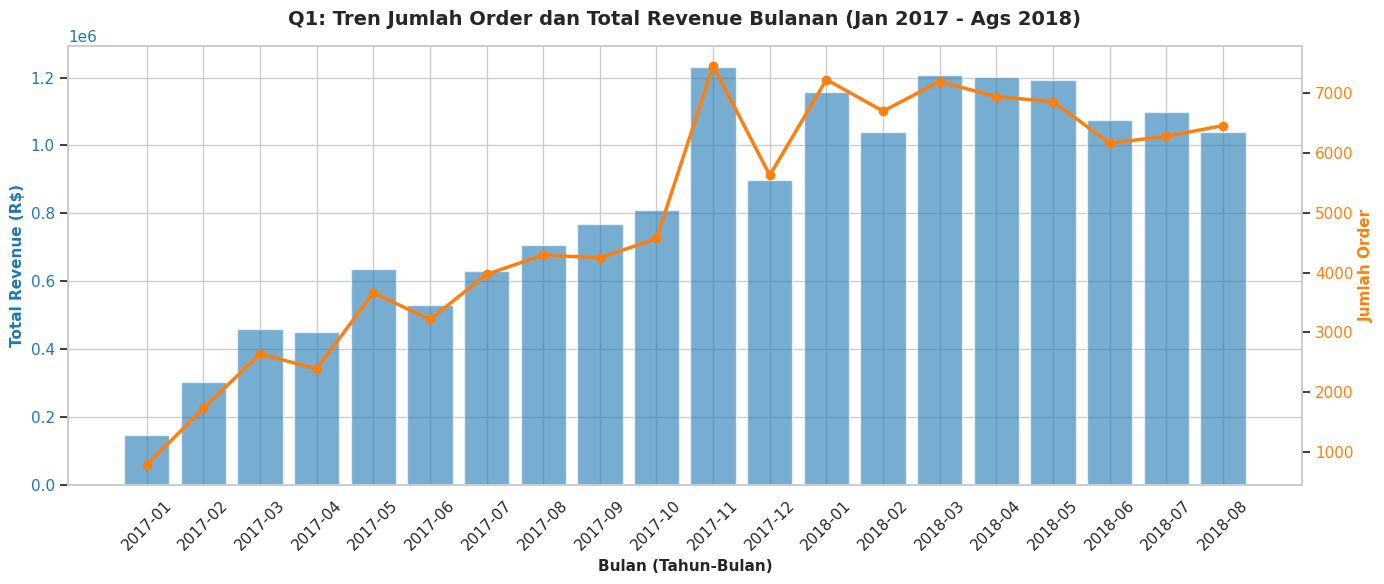

In [26]:
# ==============================================================================
# Q1: TREN BULANAN (TOTAL ORDERS & REVENUE)
# ==============================================================================
# Agregasi data per bulan
monthly_summary = order_summary.groupby('year_month').agg(
    monthly_orders=('order_id', 'count'),
    monthly_revenue=('total_revenue', 'sum')
).reset_index()

# Filter periode utama (Januari 2017 - Agustus 2018) agar data parsial 2016 & akhir 2018 tidak membiaskan tren
monthly_summary_filtered = monthly_summary[
    (monthly_summary['year_month'] >= '2017-01') &
    (monthly_summary['year_month'] <= '2018-08')
]

# Visualisasi Tren Dual-Axis
fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar Chart untuk Total Revenue
color1 = '#1f77b4'
ax1.set_xlabel('Bulan (Tahun-Bulan)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Total Revenue (R$)', color=color1, fontsize=11, fontweight='bold')
ax1.bar(monthly_summary_filtered['year_month'], monthly_summary_filtered['monthly_revenue'], color=color1, alpha=0.6, label='Revenue')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.tick_params(axis='x', rotation=45)

# Line Chart untuk Jumlah Order
ax2 = ax1.twinx()
color2 = '#ff7f0e'
ax2.set_ylabel('Jumlah Order', color=color2, fontsize=11, fontweight='bold')
ax2.plot(monthly_summary_filtered['year_month'], monthly_summary_filtered['monthly_orders'], color=color2, marker='o', linewidth=2.5, label='Jumlah Order')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False) # Matikan grid kedua agar visualisasi tetap bersih

plt.title('Q1: Tren Jumlah Order dan Total Revenue Bulanan (Jan 2017 - Ags 2018)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

📌 Q3: TOP 10 KATEGORI PRODUK TERLARIS (KUANTITAS UNiT)


,product_category_name,total_quantity,pct_quantity
7,bed_bath_table,"11,988",10.28%
43,health_beauty,"10,032",8.60%
67,sports_leisure,"9,004",7.72%
39,furniture_decor,"8,832",7.57%
15,computers_accessories,"8,150",6.99%
49,housewares,"7,380",6.33%
72,watches_gifts,"6,213",5.33%
70,telephony,"4,726",4.05%
42,garden_tools,"4,590",3.94%
5,auto,"4,400",3.77%



📌 Q4: TOP 10 KATEGORI PRODUK KONTRIBUSI REVENUE TERBESAR


,product_category_name,total_revenue,pct_revenue
43,health_beauty,"R$ 1,301,947.97",9.25%
72,watches_gifts,"R$ 1,254,322.95",8.91%
7,bed_bath_table,"R$ 1,107,249.09",7.86%
67,sports_leisure,"R$ 1,029,603.88",7.31%
15,computers_accessories,"R$ 950,053.69",6.75%
39,furniture_decor,"R$ 772,096.17",5.48%
49,housewares,"R$ 668,880.94",4.75%
20,cool_stuff,"R$ 664,637.13",4.72%
5,auto,"R$ 618,395.50",4.39%
42,garden_tools,"R$ 519,473.33",3.69%


/tmp/ipykernel_898/3491914287.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_898/3491914287.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


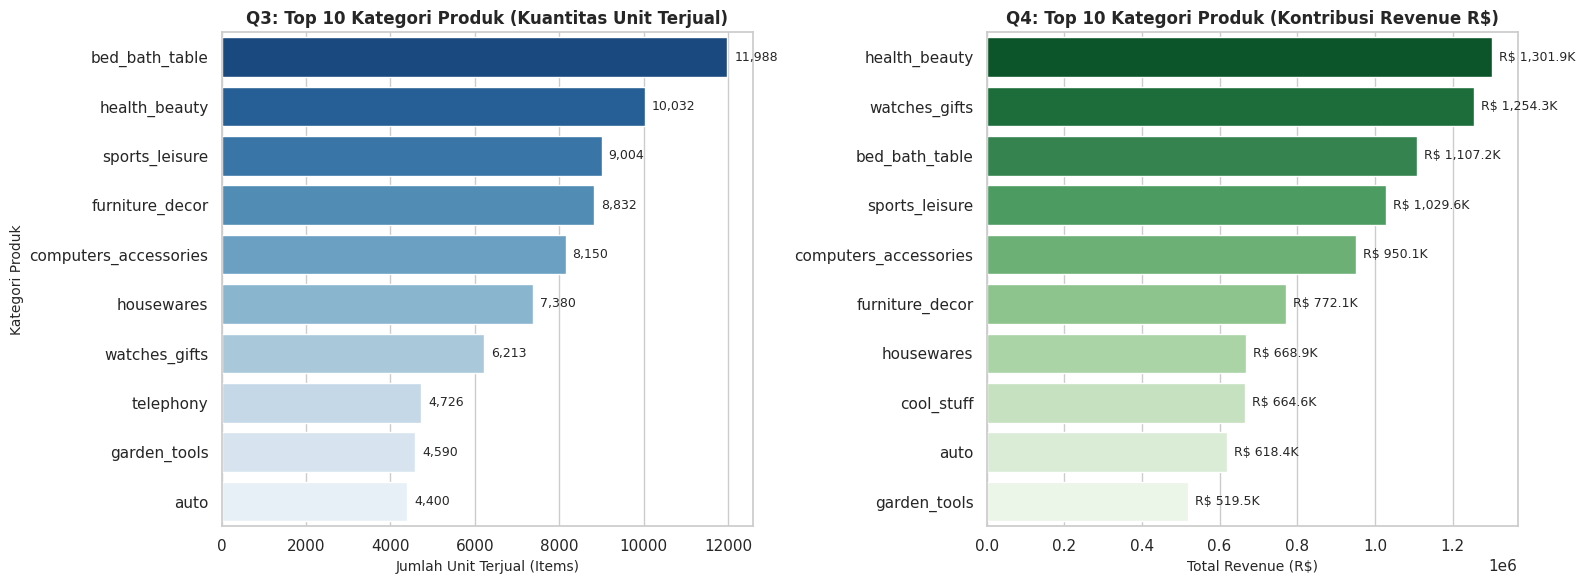

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# Q3 & Q4: AGREGASI KATEGORI PRODUK (QUANTITY & REVENUE)
# ==============================================================================
# Menghitung total unit terjual dan total revenue per kategori produk
category_summary = master_df.groupby('product_category_name').agg(
    total_quantity=('order_item_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Menghitung total keseluruhan untuk kalkulasi persentase
grand_total_qty = category_summary['total_quantity'].sum()
grand_total_rev = category_summary['total_revenue'].sum()

category_summary['pct_quantity'] = (category_summary['total_quantity'] / grand_total_qty) * 100
category_summary['pct_revenue'] = (category_summary['total_revenue'] / grand_total_rev) * 100

# Top 10 berdasarkan Kuantitas Terjual (Q3)
top_10_qty = category_summary.sort_values(by='total_quantity', ascending=False).head(10)

# Top 10 berdasarkan Revenue (Q4)
top_10_rev = category_summary.sort_values(by='total_revenue', ascending=False).head(10)


# ==============================================================================
# PRINT RINGKASAN TABEL METRIK
# ==============================================================================
print("=" * 70)
print("📌 Q3: TOP 10 KATEGORI PRODUK TERLARIS (KUANTITAS UNiT)")
print("=" * 70)
display_qty = top_10_qty.copy()
display_qty['total_quantity'] = display_qty['total_quantity'].map('{:,}'.format)
display_qty['pct_quantity'] = display_qty['pct_quantity'].map('{:.2f}%'.format)
display(display_qty[['product_category_name', 'total_quantity', 'pct_quantity']])

print("\n" + "=" * 70)
print("📌 Q4: TOP 10 KATEGORI PRODUK KONTRIBUSI REVENUE TERBESAR")
print("=" * 70)
display_rev = top_10_rev.copy()
display_rev['total_revenue'] = display_rev['total_revenue'].map('R$ {:,.2f}'.format)
display_rev['pct_revenue'] = display_rev['pct_revenue'].map('{:.2f}%'.format)
display(display_rev[['product_category_name', 'total_revenue', 'pct_revenue']])


# ==============================================================================
# VISUALISASI GRAFIK BATANG BEKAS (SIDE-BY-SIDE)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Top 10 Kuantitas (Q3)
sns.barplot(
    data=top_10_qty,
    y='product_category_name',
    x='total_quantity',
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Q3: Top 10 Kategori Produk (Kuantitas Unit Terjual)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Unit Terjual (Items)', fontsize=10)
axes[0].set_ylabel('Kategori Produk', fontsize=10)

# Annotate value di ujung bar
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'{int(width):,}',
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center',
                     xytext=(5, 0),
                     textcoords='offset points',
                     fontsize=9)

# Subplot 2: Top 10 Revenue (Q4)
sns.barplot(
    data=top_10_rev,
    y='product_category_name',
    x='total_revenue',
    ax=axes[1],
    palette='Greens_r'
)
axes[1].set_title('Q4: Top 10 Kategori Produk (Kontribusi Revenue R$)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Revenue (R$)', fontsize=10)
axes[1].set_ylabel('', fontsize=10)

# Annotate value di ujung bar
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f'R$ {width/1e3:,.1f}K',
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center',
                     xytext=(5, 0),
                     textcoords='offset points',
                     fontsize=9)

plt.tight_layout()
plt.show()

📌 Q5: TOP 10 WILAYAH CUSTOMER (STATE/NEGARA BAGIAN)


,customer_state,total_customers,pct_customers
25,SP,"39,981",41.88%
18,RJ,"12,303",12.89%
10,MG,"11,178",11.71%
22,RS,"5,249",5.50%
17,PR,"4,840",5.07%
23,SC,"3,513",3.68%
4,BA,"3,257",3.41%
6,DF,"2,062",2.16%
7,ES,"1,956",2.05%
8,GO,"1,942",2.03%



📌 Q6: PROPORSI REPEAT BUYER vs ONE-TIME BUYER


,buyer_type,count,percentage
0,One-time Buyer (1 Order),"92,507",96.95%
1,Repeat Buyer (>1 Order),"2,913",3.05%


/tmp/ipykernel_898/884125357.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


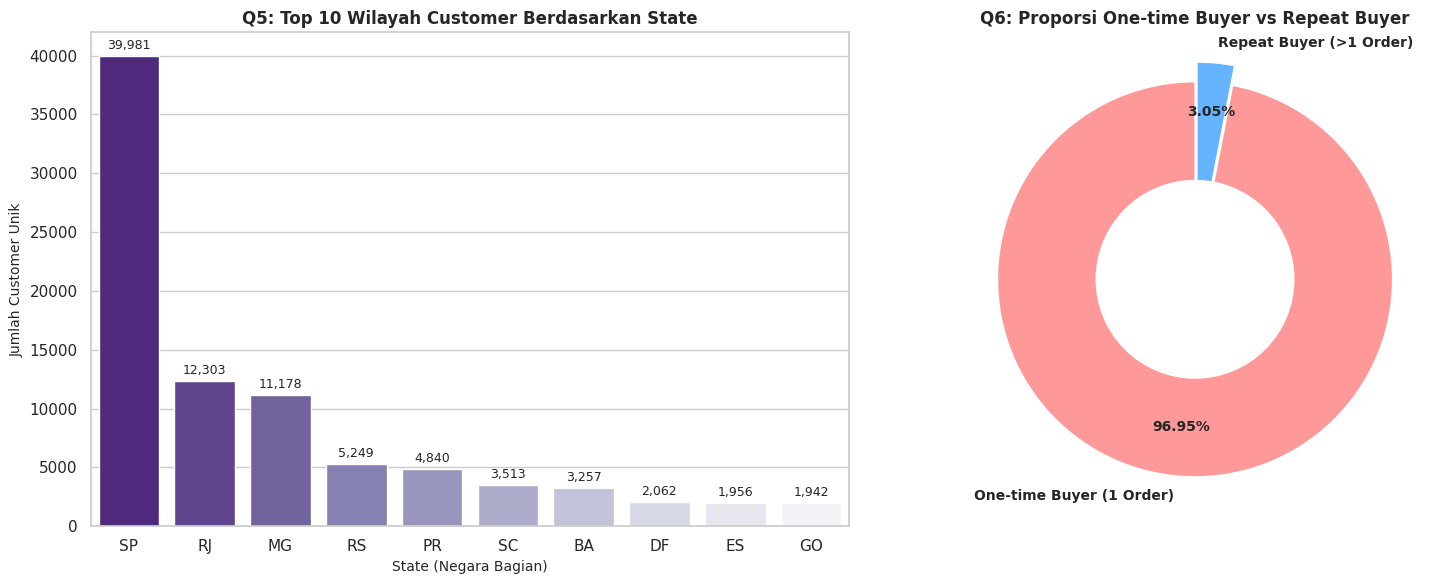

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# Q5: DISTRIBUSI WILAYAH CUSTOMER (PER STATE / NEGARA BAGIAN)
# ==============================================================================
# Agregasi jumlah unique customer per negara bagian (state)
customer_geo = master_df.groupby('customer_state')['customer_unique_id'].nunique().reset_index()
customer_geo.columns = ['customer_state', 'total_customers']

total_unique_customers = customer_geo['total_customers'].sum()
customer_geo['pct_customers'] = (customer_geo['total_customers'] / total_unique_customers) * 100

# Top 10 State dengan Pelanggan Terbanyak
top_10_states = customer_geo.sort_values(by='total_customers', ascending=False).head(10)


# ==============================================================================
# Q6: PROPORSI REPEAT BUYER vs ONE-TIME BUYER
# ==============================================================================
# Menghitung jumlah order unik per customer_unique_id
customer_orders = master_df.groupby('customer_unique_id')['order_id'].nunique().reset_index()
customer_orders.columns = ['customer_unique_id', 'total_orders']

# Pengelompokan kategori tipe pembeli
customer_orders['buyer_type'] = customer_orders['total_orders'].apply(
    lambda x: 'Repeat Buyer (>1 Order)' if x > 1 else 'One-time Buyer (1 Order)'
)

repeat_summary = customer_orders['buyer_type'].value_counts().reset_index()
repeat_summary.columns = ['buyer_type', 'count']
repeat_summary['percentage'] = (repeat_summary['count'] / repeat_summary['count'].sum()) * 100


# ==============================================================================
# PRINT TABEL RINGKASAN METRIK
# ==============================================================================
print("=" * 70)
print("📌 Q5: TOP 10 WILAYAH CUSTOMER (STATE/NEGARA BAGIAN)")
print("=" * 70)
display_states = top_10_states.copy()
display_states['total_customers'] = display_states['total_customers'].map('{:,}'.format)
display_states['pct_customers'] = display_states['pct_customers'].map('{:.2f}%'.format)
display(display_states[['customer_state', 'total_customers', 'pct_customers']])

print("\n" + "=" * 70)
print("📌 Q6: PROPORSI REPEAT BUYER vs ONE-TIME BUYER")
print("=" * 70)
display_repeat = repeat_summary.copy()
display_repeat['count'] = display_repeat['count'].map('{:,}'.format)
display_repeat['percentage'] = display_repeat['percentage'].map('{:.2f}%'.format)
display(display_repeat[['buyer_type', 'count', 'percentage']])


# ==============================================================================
# VISUALISASI GRAFIK
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Top 10 States (Q5)
sns.barplot(
    data=top_10_states,
    x='customer_state',
    y='total_customers',
    ax=axes[0],
    palette='Purples_r'
)
axes[0].set_title('Q5: Top 10 Wilayah Customer Berdasarkan State', fontsize=12, fontweight='bold')
axes[0].set_xlabel('State (Negara Bagian)', fontsize=10)
axes[0].set_ylabel('Jumlah Customer Unik', fontsize=10)

# Annotate value di atas bar
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{int(height):,}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom',
                     xytext=(0, 3),
                     textcoords='offset points',
                     fontsize=9)

# Subplot 2: Donut Chart Repeat Buyer (Q6)
colors = ['#ff9999', '#66b3ff']
wedges, texts, autotexts = axes[1].pie(
    repeat_summary['count'],
    labels=repeat_summary['buyer_type'],
    autopct='%1.2f%%',
    startangle=90,
    colors=colors,
    explode=(0, 0.1),
    pctdistance=0.75,
    textprops=dict(fontsize=10, weight='bold')
)

# Gambar lingkaran putih di tengah untuk efek Donut Chart
centre_circle = plt.Circle((0,0), 0.50, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title('Q6: Proporsi One-time Buyer vs Repeat Buyer', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

📌 Q7: DISTRIBUSI ORDER STATUS


,order_status,total_orders,pct_orders
0,delivered,"96,478",97.78%
1,shipped,"1,106",1.12%
2,canceled,461,0.47%
3,invoiced,312,0.32%
4,processing,301,0.31%
5,unavailable,6,0.01%
6,approved,2,0.00%



📌 Q8: STATISTIK DESKRIPTIF KARAKTERISTIK TRANSAKSI


,Metrik,Jumlah Item / Order,Nilai Transaksi (R$)
0,Rata-rata (Mean),1.20 item,R$ 168.69
1,Nilai Tengah (Median),1 item,R$ 107.78
2,Nilai Minimum (Min),1 item,R$ 10.07
3,Nilai Maksimum (Max),63 item,"R$ 13,664.08"


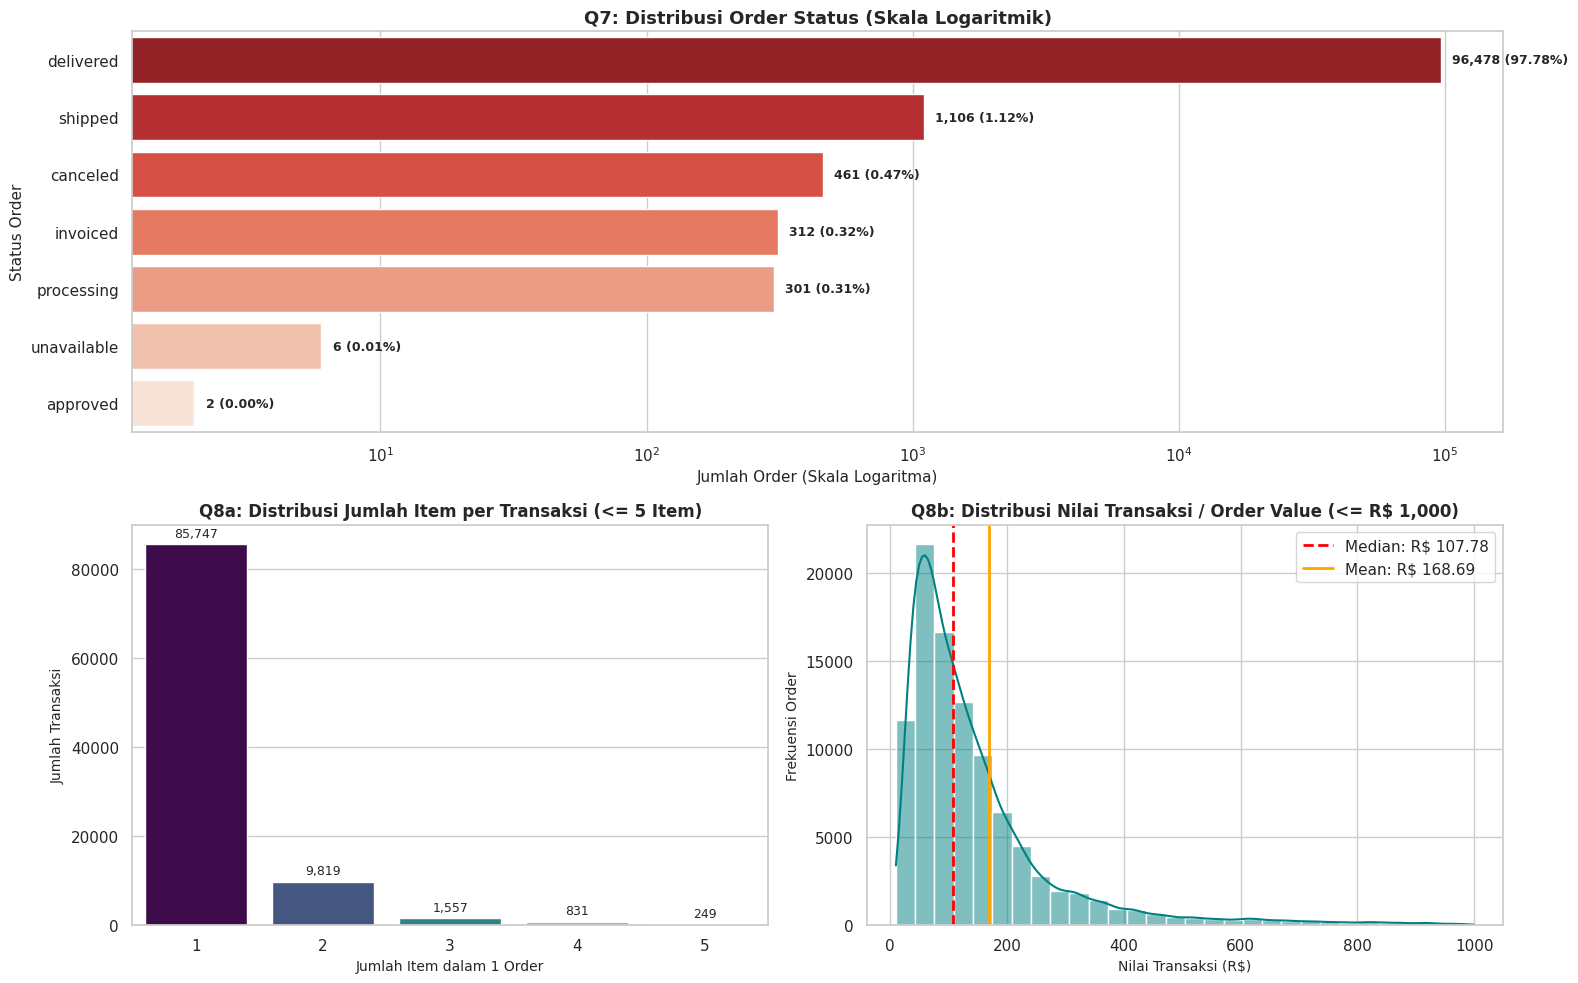

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# Q7: DISTRIBUSI ORDER STATUS
# ==============================================================================
# Agregasi order status unik per order_id (mencegah duplikasi dari multiple items)
order_status_summary = master_df.groupby('order_id')['order_status'].first().value_counts().reset_index()
order_status_summary.columns = ['order_status', 'total_orders']

total_orders_all = order_status_summary['total_orders'].sum()
order_status_summary['pct_orders'] = (order_status_summary['total_orders'] / total_orders_all) * 100


# ==============================================================================
# Q8: KARAKTERISTIK TRANSAKSI (JUMLAH ITEM & NILAI ORDER)
# ==============================================================================
# Agregasi level order untuk menghitung item count dan total belanja (produk + ongkir)
order_char = master_df.groupby('order_id').agg(
    total_items=('order_item_id', 'count'),
    total_product_value=('price', 'sum'),
    total_freight_value=('freight_value', 'sum')
).reset_index()

order_char['total_order_value'] = order_char['total_product_value'] + order_char['total_freight_value']

# Hitung statistik deskriptif Q8
item_stats = order_char['total_items'].describe()
value_stats = order_char['total_order_value'].describe()


# ==============================================================================
# PRINT TABEL RINGKASAN METRIK
# ==============================================================================
print("=" * 70)
print("📌 Q7: DISTRIBUSI ORDER STATUS")
print("=" * 70)
display_status = order_status_summary.copy()
display_status['total_orders'] = display_status['total_orders'].map('{:,}'.format)
display_status['pct_orders'] = display_status['pct_orders'].map('{:.2f}%'.format)
display(display_status)

print("\n" + "=" * 70)
print("📌 Q8: STATISTIK DESKRIPTIF KARAKTERISTIK TRANSAKSI")
print("=" * 70)
stats_summary = pd.DataFrame({
    'Metrik': ['Rata-rata (Mean)', 'Nilai Tengah (Median)', 'Nilai Minimum (Min)', 'Nilai Maksimum (Max)'],
    'Jumlah Item / Order': [
        f"{item_stats['mean']:.2f} item",
        f"{item_stats['50%']:.0f} item",
        f"{item_stats['min']:.0f} item",
        f"{item_stats['max']:.0f} item"
    ],
    'Nilai Transaksi (R$)': [
        f"R$ {value_stats['mean']:,.2f}",
        f"R$ {value_stats['50%']:,.2f}",
        f"R$ {value_stats['min']:,.2f}",
        f"R$ {value_stats['max']:,.2f}"
    ]
})
display(stats_summary)


# ==============================================================================
# VISUALISASI GRAFIK
# ==============================================================================
fig = plt.figure(figsize=(16, 10))

# Subplot 1: Order Status (Q7) - Barplot Horizontal dengan Skala Log
ax1 = plt.subplot(2, 2, (1, 2))
sns.barplot(
    data=order_status_summary,
    x='total_orders',
    y='order_status',
    hue='order_status',
    legend=False,
    ax=ax1,
    palette='Reds_r'
)
ax1.set_xscale('log') # Skala logaritma karena 'delivered' sangat mendominasi
ax1.set_title('Q7: Distribusi Order Status (Skala Logaritmik)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Jumlah Order (Skala Logaritma)', fontsize=11)
ax1.set_ylabel('Status Order', fontsize=11)

# Annotate nilai persentase pada grafik status
for p in ax1.patches:
    width = p.get_width()
    pct = (width / total_orders_all) * 100
    if width > 0:
        ax1.annotate(f'{int(width):,} ({pct:.2f}%)',
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center',
                     xytext=(8, 0),
                     textcoords='offset points',
                     fontsize=9, weight='bold')

# Subplot 2: Distribusi Jumlah Item per Order (Q8)
ax2 = plt.subplot(2, 2, 3)
sns.countplot(
    data=order_char[order_char['total_items'] <= 5],
    x='total_items',
    hue='total_items',
    legend=False,
    ax=ax2,
    palette='viridis'
)
ax2.set_title('Q8a: Distribusi Jumlah Item per Transaksi (<= 5 Item)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Jumlah Item dalam 1 Order', fontsize=10)
ax2.set_ylabel('Jumlah Transaksi', fontsize=10)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height):,}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom',
                     xytext=(0, 3),
                     textcoords='offset points',
                     fontsize=9)

# Subplot 3: Distribusi Nilai Order / Total Basket Size (Q8)
ax3 = plt.subplot(2, 2, 4)
sns.histplot(
    order_char[order_char['total_order_value'] <= 1000]['total_order_value'],
    bins=30,
    kde=True,
    ax=ax3,
    color='teal'
)
ax3.axvline(value_stats['50%'], color='red', linestyle='--', linewidth=2, label=f"Median: R$ {value_stats['50%']:.2f}")
ax3.axvline(value_stats['mean'], color='orange', linestyle='-', linewidth=2, label=f"Mean: R$ {value_stats['mean']:.2f}")
ax3.set_title('Q8b: Distribusi Nilai Transaksi / Order Value (<= R$ 1,000)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Nilai Transaksi (R$)', fontsize=10)
ax3.set_ylabel('Frekuensi Order', fontsize=10)
ax3.legend()

plt.tight_layout()
plt.show()

## Analisis RFM (Recency, Frequency, Monetary) dan Segmentasi Pelanggan berbasis

📌 RINGKASAN SEGMENTASI PELANGGAN (RFM ANALYSIS)


,Customer_Segment,Total_Customers,Avg_Recency_Days,Avg_Frequency,Avg_Monetary_R,Total_Revenue_R,Pct_Customers
4,Lost / Inactive,"23,972",370.6 hari,1.00,R$ 64.91,"R$ 1,555,933.03",25.12%
5,Low-Value Recent,"23,413",117.2 hari,1.00,R$ 64.44,"R$ 1,508,733.01",24.54%
3,High-Value New/Recent,"22,801",117.2 hari,1.00,R$ 275.59,"R$ 6,283,671.21",23.90%
2,Hibernating High-Spenders,"22,321",371.1 hari,1.00,R$ 281.33,"R$ 6,279,578.38",23.39%
1,Champions & Loyal,"1,603",117.7 hari,2.14,R$ 341.82,"R$ 547,943.14",1.68%
0,At Risk / Need Attention,"1,310",359.0 hari,2.08,R$ 357.15,"R$ 467,872.53",1.37%


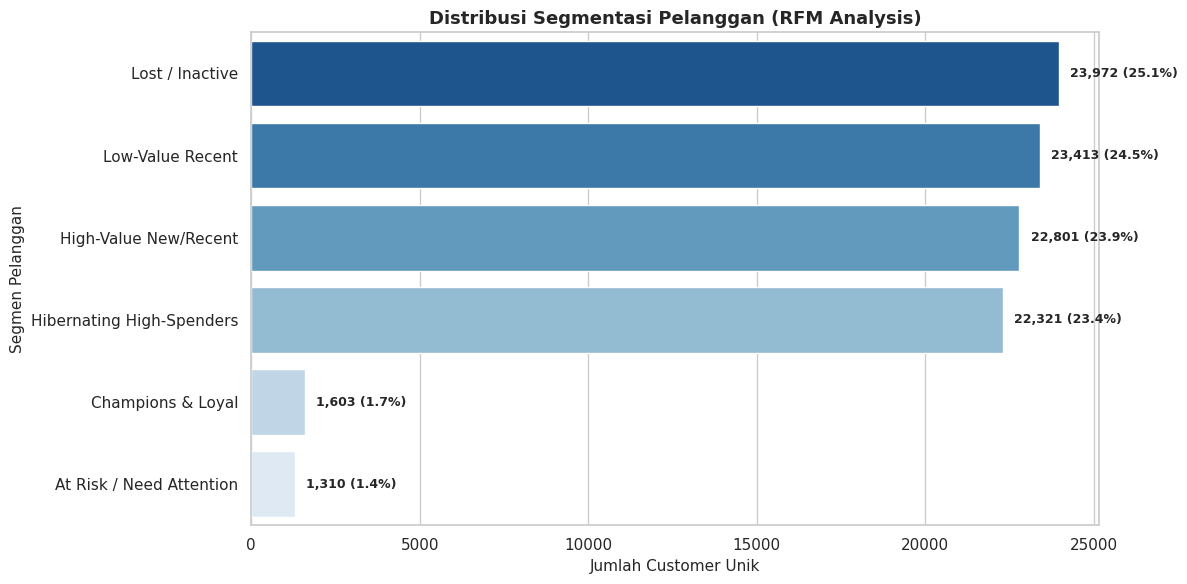

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. AGREGASI DATASET KE LEVEL ORDER DULU (PREVENT DUPLICATION)
# ==============================================================================
# Menghitung total nilai belanja (harga + ongkir) per order_id
order_level_rfm = master_df.groupby(['order_id', 'customer_unique_id']).agg(
    order_purchase_timestamp=('order_purchase_timestamp', 'max'),
    order_value=('price', 'sum'),
    freight_value=('freight_value', 'sum')
).reset_index()

order_level_rfm['total_spend'] = order_level_rfm['order_value'] + order_level_rfm['freight_value']

# ==============================================================================
# 2. KALKULASI METRIK RFM PER CUSTOMER_UNIQUE_ID
# ==============================================================================
# Menentukan tanggal acuan (snapshot date = 1 hari setelah transaksi terakhir)
snapshot_date = order_level_rfm['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = order_level_rfm.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp', lambda x: (snapshot_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('total_spend', 'sum')
).reset_index()


# ==============================================================================
# 3. SCORING RFM (1 - 4)
# ==============================================================================
# Recency: Makin kecil hari makin bagus -> Score 4 (terbaru) s/d 1 (terlama)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])

# Monetary: Makin besar belanja makin bagus -> Score 1 s/d 4
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

# Frequency: Disesuaikan karena >96% pelanggan Olist bernilai Frequency = 1
def assign_f_score(freq):
    if freq == 1:
        return 1
    elif freq == 2:
        return 3
    else:
        return 4

rfm['F_Score'] = rfm['Frequency'].apply(assign_f_score)

# Konversi skor ke integer
rfm['R_Score'] = rfm['R_Score'].astype(int)
rfm['F_Score'] = rfm['F_Score'].astype(int)
rfm['M_Score'] = rfm['M_Score'].astype(int)

# Gabungkan skor
rfm['RFM_Score_Comb'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)


# ==============================================================================
# 4. SEGMENTASI PELANGGAN BERBASIS SKOR
# ==============================================================================
def segment_customer(df):
    r = df['R_Score']
    f = df['F_Score']
    m = df['M_Score']

    if (r >= 3) and (f >= 3):
        return 'Champions & Loyal'
    elif (r >= 3) and (f == 1) and (m >= 3):
        return 'High-Value New/Recent'
    elif (r >= 3) and (f == 1) and (m < 3):
        return 'Low-Value Recent'
    elif (r <= 2) and (f >= 3):
        return 'At Risk / Need Attention'
    elif (r <= 2) and (f < 3) and (m >= 3):
        return 'Hibernating High-Spenders'
    else:
        return 'Lost / Inactive'

rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)


# ==============================================================================
# 5. RINGKASAN & VISUALISASI
# ==============================================================================
segment_summary = rfm.groupby('Customer_Segment').agg(
    Total_Customers=('customer_unique_id', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary_R=('Monetary', 'mean'),
    Total_Revenue_R=('Monetary', 'sum')
).reset_index()

total_cust = rfm['customer_unique_id'].count()
segment_summary['Pct_Customers'] = (segment_summary['Total_Customers'] / total_cust) * 100
segment_summary = segment_summary.sort_values(by='Total_Customers', ascending=False)

print("=" * 80)
print("📌 RINGKASAN SEGMENTASI PELANGGAN (RFM ANALYSIS)")
print("=" * 80)
display_summary = segment_summary.copy()
display_summary['Total_Customers'] = display_summary['Total_Customers'].map('{:,}'.format)
display_summary['Pct_Customers'] = display_summary['Pct_Customers'].map('{:.2f}%'.format)
display_summary['Avg_Recency_Days'] = display_summary['Avg_Recency_Days'].map('{:.1f} hari'.format)
display_summary['Avg_Frequency'] = display_summary['Avg_Frequency'].map('{:.2f}'.format)
display_summary['Avg_Monetary_R'] = display_summary['Avg_Monetary_R'].map('R$ {:,.2f}'.format)
display_summary['Total_Revenue_R'] = display_summary['Total_Revenue_R'].map('R$ {:,.2f}'.format)
display(display_summary)

# Visualisasi Bar Chart Segmentasi
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=segment_summary,
    y='Customer_Segment',
    x='Total_Customers',
    hue='Customer_Segment',
    legend=False,
    palette='Blues_r'
)
plt.title('Distribusi Segmentasi Pelanggan (RFM Analysis)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Customer Unik', fontsize=11)
plt.ylabel('Segmen Pelanggan', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    pct = (width / total_cust) * 100
    if width > 0:
        ax.annotate(f'{int(width):,} ({pct:.1f}%)',
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center',
                     xytext=(8, 0),
                     textcoords='offset points',
                     fontsize=9, weight='bold')

plt.tight_layout()
plt.show()

## menganalisis durasi pengiriman, persentase keterlambatan (late delivery rate)

📌 SUMMARY PERFORMA LOGISTIK & PENGIRIMAN OLIST
Total Pesanan Terkirim (Delivered) : 95,824 order
Rata-rata Durasi Pengiriman Aktual  : 12.1 hari
Rata-rata Estimasi Pengiriman       : 23.4 hari
Jumlah Pesanan Terlambat (Late)     : 6,381 order (6.66%)

📌 DAMPAK KETERLAMBATAN TERHADAP RATA-RATA REVIEW SCORE


,delivery_status,total_orders,avg_review_score,median_review_score
0,Late,"6,381",2.27,1.0
1,On-Time / Early,"89,443",4.29,5.0


/tmp/ipykernel_898/4008386338.py:148: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


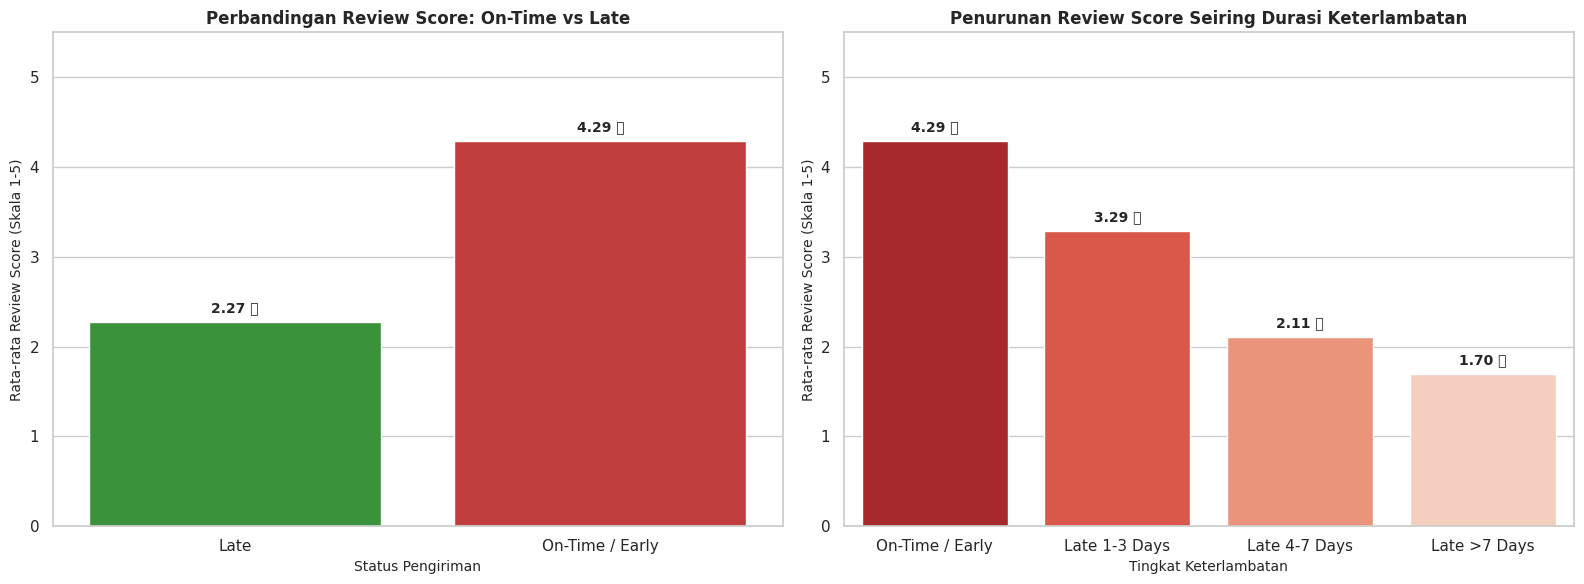

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. FILTER ORDER STATUS 'DELIVERED' & AGREGASI LEVEL ORDER_ID
# ==============================================================================
# Hanya analisis pesanan yang berhasil terkirim
delivered_df = master_df[master_df['order_status'] == 'delivered'].copy()

delivery_analysis = delivered_df.groupby('order_id').agg(
    purchase_date=('order_purchase_timestamp', 'first'),
    delivered_date=('order_delivered_customer_date', 'first'),
    estimated_date=('order_estimated_delivery_date', 'first'),
    review_score=('review_score', 'first')
).reset_index()

# Hapus baris yang tidak memiliki tanggal pengiriman aktual atau review score
delivery_analysis = delivery_analysis.dropna(subset=['delivered_date', 'review_score']).copy()


# ==============================================================================
# 2. KALKULASI METRIK PERFORMA PENGIRIMAN
# ==============================================================================
# Menghitung durasi aktual, estimasi, dan hari keterlambatan
delivery_analysis['actual_delivery_days'] = (delivery_analysis['delivered_date'] - delivery_analysis['purchase_date']).dt.days
delivery_analysis['estimated_delivery_days'] = (delivery_analysis['estimated_date'] - delivery_analysis['purchase_date']).dt.days
delivery_analysis['delay_days'] = (delivery_analysis['delivered_date'] - delivery_analysis['estimated_date']).dt.days

# Status pengiriman: Late jika delay_days > 0
delivery_analysis['delivery_status'] = delivery_analysis['delay_days'].apply(
    lambda x: 'Late' if x > 0 else 'On-Time / Early'
)

# Kategori keterlambatan bertingkat
def categorize_delay(days):
    if days <= 0:
        return 'On-Time / Early'
    elif days <= 3:
        return 'Late 1-3 Days'
    elif days <= 7:
        return 'Late 4-7 Days'
    else:
        return 'Late >7 Days'

delivery_analysis['delay_category'] = delivery_analysis['delay_days'].apply(categorize_delay)


# ==============================================================================
# 3. STATISTIK PERFORMA & IMPACT ANALYSIS
# ==============================================================================
total_delivered = len(delivery_analysis)
late_count = (delivery_analysis['delivery_status'] == 'Late').sum()
late_pct = (late_count / total_delivered) * 100

avg_actual = delivery_analysis['actual_delivery_days'].mean()
avg_estimated = delivery_analysis['estimated_delivery_days'].mean()

print("=" * 80)
print("📌 SUMMARY PERFORMA LOGISTIK & PENGIRIMAN OLIST")
print("=" * 80)
print(f"Total Pesanan Terkirim (Delivered) : {total_delivered:,} order")
print(f"Rata-rata Durasi Pengiriman Aktual  : {avg_actual:.1f} hari")
print(f"Rata-rata Estimasi Pengiriman       : {avg_estimated:.1f} hari")
print(f"Jumlah Pesanan Terlambat (Late)     : {late_count:,} order ({late_pct:.2f}%)")
print("=" * 80)

# Agregasi Review Score berdasarkan Status Pengiriman
review_impact = delivery_analysis.groupby('delivery_status').agg(
    total_orders=('order_id', 'count'),
    avg_review_score=('review_score', 'mean'),
    median_review_score=('review_score', 'median')
).reset_index()

print("\n" + "=" * 80)
print("📌 DAMPAK KETERLAMBATAN TERHADAP RATA-RATA REVIEW SCORE")
print("=" * 80)
display_impact = review_impact.copy()
display_impact['total_orders'] = display_impact['total_orders'].map('{:,}'.format)
display_impact['avg_review_score'] = display_impact['avg_review_score'].map('{:.2f}'.format)
display(display_impact)


# ==============================================================================
# 4. VISUALISASI GRAFIK
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Review Score On-Time vs Late
sns.barplot(
    data=review_impact,
    x='delivery_status',
    y='avg_review_score',
    hue='delivery_status',
    legend=False,
    ax=axes[0],
    palette=['#2ca02c', '#d62728']
)
axes[0].set_ylim(0, 5.5)
axes[0].set_title('Perbandingan Review Score: On-Time vs Late', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Status Pengiriman', fontsize=10)
axes[0].set_ylabel('Rata-rata Review Score (Skala 1-5)', fontsize=10)

for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f} ⭐',
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom',
                         xytext=(0, 5),
                         textcoords='offset points',
                         fontsize=10, weight='bold')

# Subplot 2: Penurunan Review Score berdasarkan Durasi Keterlambatan
delay_cat_summary = delivery_analysis.groupby('delay_category').agg(
    avg_review=('review_score', 'mean'),
    total=('order_id', 'count')
).reindex(['On-Time / Early', 'Late 1-3 Days', 'Late 4-7 Days', 'Late >7 Days']).reset_index()

sns.barplot(
    data=delay_cat_summary,
    x='delay_category',
    y='avg_review',
    hue='delay_category',
    legend=False,
    ax=axes[1],
    palette='Reds_r'
)
axes[1].set_ylim(0, 5.5)
axes[1].set_title('Penurunan Review Score Seiring Durasi Keterlambatan', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tingkat Keterlambatan', fontsize=10)
axes[1].set_ylabel('Rata-rata Review Score (Skala 1-5)', fontsize=10)

for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f} ⭐',
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom',
                         xytext=(0, 5),
                         textcoords='offset points',
                         fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

## Payment Method & Installments Analysis

📌 Q1: RINGKASAN METODE PEMBAYARAN


,payment_type,total_transactions,total_value,avg_value,pct_transactions,pct_value
1,credit_card,"76,278","R$ 12,436,226.57",R$ 163.04,74.02%,78.48%
0,boleto,"19,614","R$ 2,842,240.16",R$ 144.91,19.03%,17.94%
3,voucher,"5,642","R$ 352,707.71",R$ 62.51,5.47%,2.23%
2,debit_card,"1,522","R$ 215,105.73",R$ 141.33,1.48%,1.36%



📌 Q2: DISTRIBUSI PENGGUNAAN CICILAN (CREDIT CARD)


,installment_group,total_orders,avg_payment_value,pct_orders
0,1x (Bayar Lunas),"25,268",R$ 95.73,33.13%
1,2x - 3x Cicilan,"22,744",R$ 134.20,29.82%
2,4x - 6x Cicilan,"16,149",R$ 181.29,21.17%
3,7x - 10x Cicilan,"11,778",R$ 332.49,15.44%
4,> 10x Cicilan,339,R$ 357.95,0.44%


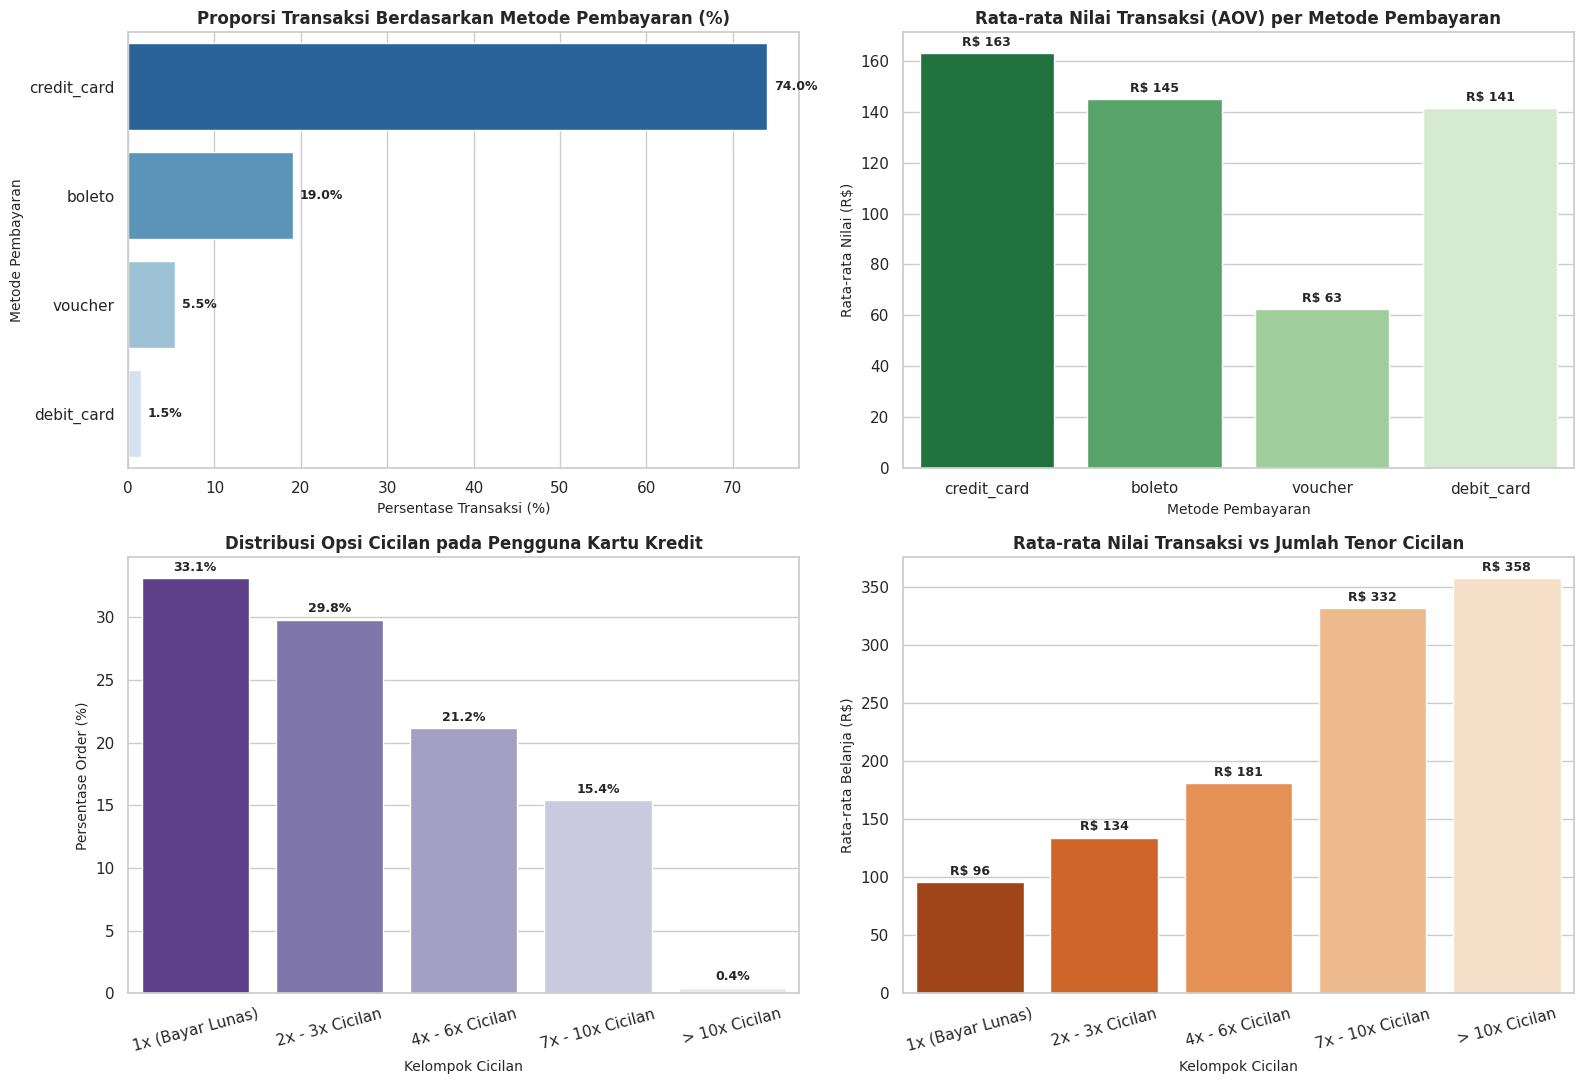

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. DEDUPLIKASI TABEL PEMBAYARAN (MENCEGAH DUPLIKASI DARI MULTIPLE ITEMS)
# ==============================================================================
# Mengambil entitas unik level pembayaran per order
payment_df = master_df[[
    'order_id', 'payment_sequential', 'payment_type',
    'payment_installments', 'payment_value'
]].drop_duplicates().copy()

# Hapus kategori 'not_defined' jika ada
payment_df = payment_df[payment_df['payment_type'] != 'not_defined']


# ==============================================================================
# 2. ANALISIS METODE PEMBAYARAN (TRANSAKSI vs TOTAL VALUE)
# ==============================================================================
payment_type_summary = payment_df.groupby('payment_type').agg(
    total_transactions=('order_id', 'count'),
    total_value=('payment_value', 'sum'),
    avg_value=('payment_value', 'mean')
).reset_index()

total_trans_all = payment_type_summary['total_transactions'].sum()
total_val_all = payment_type_summary['total_value'].sum()

payment_type_summary['pct_transactions'] = (payment_type_summary['total_transactions'] / total_trans_all) * 100
payment_type_summary['pct_value'] = (payment_type_summary['total_value'] / total_val_all) * 100

payment_type_summary = payment_type_summary.sort_values(by='total_transactions', ascending=False)

print("=" * 80)
print("📌 Q1: RINGKASAN METODE PEMBAYARAN")
print("=" * 80)
display_pay = payment_type_summary.copy()
display_pay['total_transactions'] = display_pay['total_transactions'].map('{:,}'.format)
display_pay['pct_transactions'] = display_pay['pct_transactions'].map('{:.2f}%'.format)
display_pay['total_value'] = display_pay['total_value'].map('R$ {:,.2f}'.format)
display_pay['pct_value'] = display_pay['pct_value'].map('{:.2f}%'.format)
display_pay['avg_value'] = display_pay['avg_value'].map('R$ {:,.2f}'.format)
display(display_pay)


# ==============================================================================
# 3. ANALISIS CICILAN (FOKUS CREDIT CARD)
# ==============================================================================
credit_card_df = payment_df[payment_df['payment_type'] == 'credit_card'].copy()

# Pengelompokan jumlah cicilan
def categorize_installments(ins):
    if ins == 1:
        return '1x (Bayar Lunas)'
    elif 2 <= ins <= 3:
        return '2x - 3x Cicilan'
    elif 4 <= ins <= 6:
        return '4x - 6x Cicilan'
    elif 7 <= ins <= 10:
        return '7x - 10x Cicilan'
    else:
        return '> 10x Cicilan'

credit_card_df['installment_group'] = credit_card_df['payment_installments'].apply(categorize_installments)

installment_summary = credit_card_df.groupby('installment_group').agg(
    total_orders=('order_id', 'count'),
    avg_payment_value=('payment_value', 'mean')
).reindex([
    '1x (Bayar Lunas)', '2x - 3x Cicilan',
    '4x - 6x Cicilan', '7x - 10x Cicilan', '> 10x Cicilan'
]).reset_index()

total_cc_orders = installment_summary['total_orders'].sum()
installment_summary['pct_orders'] = (installment_summary['total_orders'] / total_cc_orders) * 100

print("\n" + "=" * 80)
print("📌 Q2: DISTRIBUSI PENGGUNAAN CICILAN (CREDIT CARD)")
print("=" * 80)
display_ins = installment_summary.copy()
display_ins['total_orders'] = display_ins['total_orders'].map('{:,}'.format)
display_ins['pct_orders'] = display_ins['pct_orders'].map('{:.2f}%'.format)
display_ins['avg_payment_value'] = display_ins['avg_payment_value'].map('R$ {:,.2f}'.format)
display(display_ins)


# ==============================================================================
# 4. VISUALISASI GRAFIK (4 SUBPLOTS)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Subplot 1: Proporsi Transaksi per Metode Pembayaran
sns.barplot(
    data=payment_type_summary,
    x='pct_transactions',
    y='payment_type',
    hue='payment_type',
    legend=False,
    ax=axes[0, 0],
    palette='Blues_r'
)
axes[0, 0].set_title('Proporsi Transaksi Berdasarkan Metode Pembayaran (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Persentase Transaksi (%)', fontsize=10)
axes[0, 0].set_ylabel('Metode Pembayaran', fontsize=10)

for p in axes[0, 0].patches:
    width = p.get_width()
    if width > 0:
        axes[0, 0].annotate(f'{width:.1f}%',
                            (width, p.get_y() + p.get_height() / 2.),
                            ha='left', va='center',
                            xytext=(5, 0),
                            textcoords='offset points',
                            fontsize=9, weight='bold')

# Subplot 2: Rata-rata Nilai Transaksi (AOV) per Metode Pembayaran
sns.barplot(
    data=payment_type_summary,
    x='payment_type',
    y='avg_value',
    hue='payment_type',
    legend=False,
    ax=axes[0, 1],
    palette='Greens_r'
)
axes[0, 1].set_title('Rata-rata Nilai Transaksi (AOV) per Metode Pembayaran', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Metode Pembayaran', fontsize=10)
axes[0, 1].set_ylabel('Rata-rata Nilai (R$)', fontsize=10)

for p in axes[0, 1].patches:
    height = p.get_height()
    if height > 0:
        axes[0, 1].annotate(f'R$ {height:,.0f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom',
                            xytext=(0, 3),
                            textcoords='offset points',
                            fontsize=9, weight='bold')

# Subplot 3: Distribusi Penggunaan Cicilan Kartu Kredit
sns.barplot(
    data=installment_summary,
    x='installment_group',
    y='pct_orders',
    hue='installment_group',
    legend=False,
    ax=axes[1, 0],
    palette='Purples_r'
)
axes[1, 0].set_title('Distribusi Opsi Cicilan pada Pengguna Kartu Kredit', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Kelompok Cicilan', fontsize=10)
axes[1, 0].set_ylabel('Persentase Order (%)', fontsize=10)
axes[1, 0].tick_params(axis='x', rotation=15)

for p in axes[1, 0].patches:
    height = p.get_height()
    if height > 0:
        axes[1, 0].annotate(f'{height:.1f}%',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom',
                            xytext=(0, 3),
                            textcoords='offset points',
                            fontsize=9, weight='bold')

# Subplot 4: Hubungan Jumlah Cicilan dengan Nilai Transaksi
sns.barplot(
    data=installment_summary,
    x='installment_group',
    y='avg_payment_value',
    hue='installment_group',
    legend=False,
    ax=axes[1, 1],
    palette='Oranges_r'
)
axes[1, 1].set_title('Rata-rata Nilai Transaksi vs Jumlah Tenor Cicilan', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Kelompok Cicilan', fontsize=10)
axes[1, 1].set_ylabel('Rata-rata Belanja (R$)', fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=15)

for p in axes[1, 1].patches:
    height = p.get_height()
    if height > 0:
        axes[1, 1].annotate(f'R$ {height:,.0f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom',
                            xytext=(0, 3),
                            textcoords='offset points',
                            fontsize=9, weight='bold')

plt.tight_layout()
plt.show()

#Laporan Eksekutif: Analisis Kinerja Penjualan & Strategi Pertumbuhan Olist E-Commerce
##1. Ringkasan Eksekutif (Executive Summary)
Laporan ini menyajikan evaluasi komprehensif terhadap kinerja operasional, perilaku pelanggan, logistik, dan metode pembayaran pada platform marketplace Olist E-Commerce (Brasil) berdasarkan transaksi periode 2016–2018 (sekitar 100.000 pesanan).

Secara keseluruhan, Olist menunjukkan pertumbuhan volume transaksi dan Revenue yang kuat, dipicu oleh tren penjualan musiman (Black Friday) dan dominasi pasar di wilayah Tenggara Brasil (São Paulo, Rio de Janeiro, Minas Gerais). Namun, analisis mengidentifikasi dua kerentanan kritis yang berpotensi menghambat skalabilitas jangka panjang:
1. Tingkat Retensi Pelanggan yang Sangat Rendah: Lebih dari 97% pelanggan adalah One-time Buyer, menandakan tingginya Customer Acquisition Cost (CAC) tanpa imbuhan Customer Lifetime Value (CLV) yang optimal.

2. Sensititvitas Kepuasan Terhadap Logistik: Terdapat korelasi langsung antara keterlambatan pengiriman (late delivery) dengan anjloknya skor ulasan pelanggan (review score dari ~4.2 ⭐ turun menjadi ~2.2 ⭐).
##2. Temuan Utama (Key Insight)
###A. Kinerja Penjualan & Tren Musiman (Sales & Revenue Dynamics)
- Skala & AOV: Olist membukukan total
transaksi mendekati ~100.000 order dengan Average Order Value (AOV) sebesar R$ 160–168 (termasuk komponen ongkir).

- Lonjakan Musiman: Pertumbuhan penjualan berlangsung stabil sejak awal 2017 dan mencapai puncak tertinggi (peak sales) pada November 2017 berkat momentum Black Friday.
###B. Performa Kategori Produk (Volume vs Value Drivers)
- Pendorong Volume (High Volume): Kategori produk kebutuhan rumah tangga seperti bed_bath_table (cama_mesa_banho) dan sports_leisure mendominasi kuantitas unit terjual.

- Pendorong Revenue (High Value): Kategori seperti health_beauty, watches_gifts, dan computers_accessories memberikan kontribusi Revenue terbesar karena nilai transaksi per unit yang lebih tinggi.
###C. Perilaku Pelanggan & Geografi (Customer Behavior & Geography)
- Konsentrasi Geografis: Pasar terpusat di wilayah Tenggara Brasil, di mana State São Paulo (SP) sendiri menyumbang lebih dari 40% total basis pelanggan.

- Tantangan Retensi: Pembelian berulang (repeat purchase) sangat minim (< 3%). Olist saat ini berfungsi murni sebagai acquisition channel, belum sebagai platform yang membangun loyalitas merek.
###D. Dampak Performa Logitsik Terhadap Ulasan (Logistics VS Rating)
- Tingkat Keterlambatan (SLA): Sekitar 6%–8% pesanan mengalami keterlambatan melebihi tanggal estimasi (estimated delivery date).

- Anjloknya Rating: Pesanan yang tiba tepat waktu memperoleh rata-rata ulasan 4.25 ⭐. Namun, ketika terjadi keterlambatan, rating merosot hingga 2.25 ⭐ (dan jatuh di bawah 1.5 ⭐ jika keterlambatan melebihi 7 hari).
###E. Perilaku Pembayaran & Tenor Cicilan (Payments & Installments)
- Dominasi Kartu Kredit: Kartu Kredit menyumbang 75% transaksi dan >78% total revenue, disusul oleh Boleto Bancário (~19%).

- Leverage Daya Beli via Cicilan: Lebih dari 50% pengguna Kartu Kredit memanfaatkan opsi cicilan. Terdapat korelasi positif yang kuat: transaksi bayar lunas (1x) memiliki rata-rata belanja R$ 95, sedangkan konsumen yang mengambil cicilan >10x memiliki rata-rata belanja melebihi R$ 400.
#3. Rekomendasi Strategi Bisnis (Actionable Recomendations)
##1. Program Retensi & Strategi CRM Tersegmentasi
- Fokus Segmen High-Value Recent: Pelanggan baru dengan nilai belanja tinggi harus segera dimasukkan ke dalam alur onboarding otomatis (email/WhatsApp marketing) dalam 14–30 hari pertama pasca-pembelian.

- Insentif Pembelian Kedua: Berikan kupon diskon ongkir atau cashback khusus untuk transaksi kedua guna mengikis dominasi 97% One-time Buyer.
##2. Mitigasi Risiko Logistik & Manajemen Ekspektasi Konsumen
- Hub Fulfillment Regional: Mengingat konsentrasi pasar berada di SP, RJ, dan MG, Olist perlu mendorong skema consignment / fulfillment center di wilayah tersebut untuk memangkas lead time.

- Penyesuaian Estimasi Pengiriman (Buffer Dynamic): Untuk pengiriman lintas wilayah dengan jarak jauh, tambahkan buffer estimasi 2–3 hari agar ekspektasi pelanggan tetap terjaga dan ulasan bintang 1 dapat ditekan.

- Notifikasi Proaktif: Kirimkan notifikasi keterlambatan beserta voucher kompensasi sebelum pelanggan memberikan ulasan negatif.
##3. Peningkatan Nilai Keranjang Belanja (Basket Size Expansion)
- Bundling & Cross-Selling: Lebih dari 89% transaksi hanya berisi 1 item. Implementasikan fitur rekomendasi produk ("Frequently Bought Together") antara produk favorit (misal: bed_bath_table) dengan produk komplementer bernilai tinggi.

- Promosi Berbasis Tenor Cicilan: Kampanyekan opsi cicilan bebas bunga (0% interest installments) khusus untuk kategori barang bernilai tinggi (watches, electronics, home appliances) untuk mendorong pembeli meningkatkan nilai keranjang belanja mereka.
##4. Optimasi Corong Pembayaran (Checkout Funnel)
- Sistem Pengingat Boleto Bancário: Karena transaksi Boleto membutuhkan waktu jatuh tempo, buat sistem pengingat otomatis via SMS/WhatsApp sebelum tenggat pembayaran habis untuk mengurangi angka pemesanan yang kedaluwarsa.

In [36]:
# Save master_df ke file CSV
master_df.to_csv('olist_master_clean.csv', index=False)

# Download file langsung ke komputer
from google.colab import files
files.download('olist_master_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>